# 05 Where does the model go wrong? Error analysis (M6)

**Owner:** Mahmoud · **Due:** CP4 (Sun 8 Nov) · **Covers:** proposal (errors by district, hour, distance, test day;
"do errors rise at meal peaks?"), Lec 2 (subgroup evaluation), ALIGNMENT §5 (ethics: do some areas get worse ETAs?)

**Model:** the final HGB from `python -m experiments.final` (frozen settings in `experiments/final_params/hgb.json`).
I read its saved predictions, so nothing is refit here.

- `results/final/cv/hgb/`: the 4 CV folds on the training days (any time)
- `results/final/test/hgb/`: the test days 23 to 24 Oct, written **once** at CP4 by
  `python -m experiments.final --eval test --i-am-at-cp4`

Every section shows CV, and adds the test days when they exist.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common.config import LATE_THRESHOLD_MIN, RESULTS
from common.evaluate import DIST_BINS

FIG = ROOT / "figures" / "results"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C = {"CV": plt.cm.viridis(0.3), "test": plt.cm.viridis(0.75)}

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")

def load(ev, model="hgb"):
    path = RESULTS / "final" / ev / model / "predictions.parquet"
    if not path.exists():
        return None
    p = pd.read_parquet(path)
    p["err"] = p["pred"] - p["y"]          # > 0: we predicted too long, < 0: too short (the order was late)
    p["abs_err"] = p["err"].abs()
    p["dist_bin"] = pd.cut(p["dist_km"], DIST_BINS, right=False)
    p["peak"] = np.where(p["hour"] == 11, "lunch peak (11)",
                np.where(p["hour"].between(17, 19), "dinner peak (17-19)", "off-peak"))
    return p

runs = {ev: p for ev in ["CV", "test"] if (p := load(ev.lower())) is not None}
assert "CV" in runs, "run `python -m experiments.final` first"
for ev, p in runs.items():
    print(f"{ev:4s}: {len(p):,} orders, MAE {p.abs_err.mean():.2f}, mean error {p.err.mean():+.2f} min, "
          f"late > {LATE_THRESHOLD_MIN} min {(p.err < -LATE_THRESHOLD_MIN).mean():.1%}")
if "test" not in runs:
    print("test days not scored yet (CP4): sections show CV only")

CV  : 275,962 orders, MAE 6.25, mean error -1.04 min, late > 5 min 27.6%
test: 139,787 orders, MAE 6.49, mean error -1.37 min, late > 5 min 29.4%


## 1. Do errors rise at meal peaks? (proposal expectation)

CV               test            
                          n   mae  bias      n   mae  bias
peak                                                      
dinner peak (17-19)   81657  6.67 -1.22  40360  6.86 -1.20
lunch peak (11)       47070  7.04 -0.16  23058  7.22 -0.47
off-peak             147235  5.76 -1.21  76369  6.08 -1.73

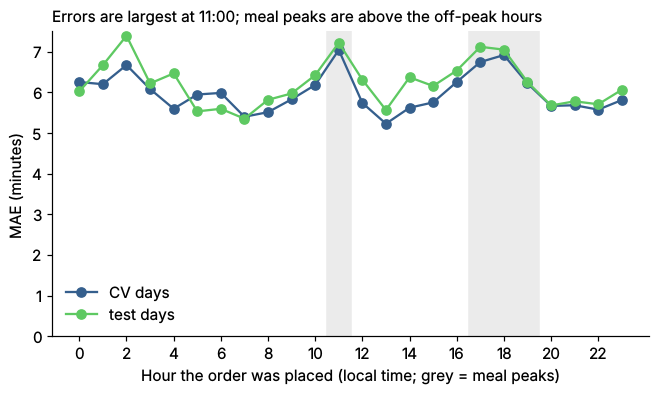

In [2]:
def by(col):
    return pd.concat({ev: p.groupby(col, observed=True).agg(n=("y", "size"), mae=("abs_err", "mean"),
                                                            bias=("err", "mean"))
                      for ev, p in runs.items()}, axis=1)

hour = by("hour")
peak = by("peak")
display(peak.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for h in [11, 17, 18, 19]:
    ax.axvspan(h - 0.5, h + 0.5, color="0.92", zorder=0)
for ev in runs:
    ax.plot(hour.index, hour[ev]["mae"], marker="o", color=C[ev], label=f"{ev} days")
worst = hour["CV"]["mae"].idxmax()
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour the order was placed (local time; grey = meal peaks)")
ax.set_ylabel("MAE (minutes)")
ax.set_ylim(0, None)
ax.set_title(f"Errors are largest at {worst}:00; meal peaks are above the off-peak hours", fontsize=10, loc="left")
ax.legend(frameon=False)
save(fig, "errors_by_hour")
plt.show()

**Reading:** yes, errors rise at meal peaks, on CV and on the test days. On the test days MAE is 7.22 min at the
11:00 lunch peak and 6.86 at the 17:00 to 19:00 dinner peak, against 6.08 off-peak (CV: 7.04, 6.67, 5.76). So the
proposal's guess held. Among the busy hours, 11:00 is the worst in both. A few night hours look bad on the test
days too, but they have few orders, so I don't read much into them.

## 2. Longer trips, bigger errors?

CV                test             
                 n    mae  bias      n    mae  bias
dist_bin                                           
[0.0, 1.0)   83358   5.44 -1.15  42785   5.61 -1.30
[1.0, 2.0)  109830   6.17 -1.06  55159   6.39 -1.43
[2.0, 3.0)   63666   6.85 -0.80  31780   7.15 -1.26
[3.0, 4.0)   13117   7.50 -0.75   6815   7.96 -1.32
[4.0, 5.0)    3389   9.06 -1.66   1861   9.42 -2.01
[5.0, 7.0)    2134  10.45 -1.55   1168  11.10 -2.35
[7.0, inf)     468  12.66 -6.89    219  14.37 -8.55

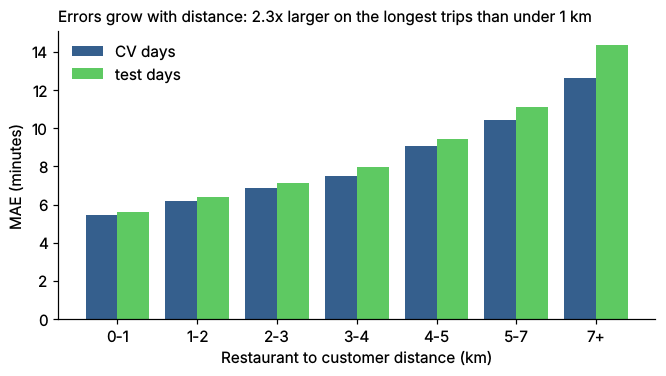

In [3]:
dist = by("dist_bin")
display(dist.round(2))

fig, ax = plt.subplots(figsize=(7, 3.4))
labels = [f"{iv.left:g}-{iv.right:g}" if np.isfinite(iv.right) else f"{iv.left:g}+" for iv in dist.index]
x = np.arange(len(dist))
w = 0.8 / len(runs)
for i, ev in enumerate(runs):
    ax.bar(x + i * w - 0.4 + w / 2, dist[ev]["mae"], w, color=C[ev], label=f"{ev} days")
ax.set_xticks(x, labels)
ax.set_xlabel("Restaurant to customer distance (km)")
ax.set_ylabel("MAE (minutes)")
grow = dist["CV"]["mae"].iloc[-1] / dist["CV"]["mae"].iloc[0]
ax.set_title(f"Errors grow with distance: {grow:.1f}x larger on the longest trips than under 1 km",
             fontsize=10, loc="left")
ax.legend(frameon=False)
save(fig, "errors_by_distance")
plt.show()

**Reading:** errors grow with distance, from 5.61 min under 1 km to 9.42 at 4 to 5 km and 14.37 over 7 km on the
test days (CV: 5.44, 9.06, 12.66). Every distance bin is a bit worse on the test days than on CV. Most orders (70%)
are under 2 km, which keeps the overall MAE low. The few trips over 7 km (219 test orders) are about 8.6 min later
than we predict on average.

## 3. Do some areas get worse ETAs? (Lec 2 subgroups, ethics)

CV               test            
              n   mae  bias      n   mae  bias
district                                      
18        10558  4.16 -1.19   5335  4.37 -1.22
6         20281  4.56 -0.30   9712  4.69 -1.61
20         3706  4.91 -0.43   1994  5.19 -0.89
3         11186  5.20 -1.02   5779  4.99 -0.03
10         2839  5.41 -1.04   1451  5.27  0.11
21         2599  5.67 -1.11   1363  9.04 -6.11
17         3323  5.73 -1.12   1666  5.76 -0.93
14         2902  5.87 -1.41   1529  6.47 -3.05
8          9077  5.94 -2.23   4804  5.87 -1.61
19         5629  6.05 -1.57   2766  6.26 -0.99
7         19658  6.22 -1.44  10307  6.40 -1.16
4          7674  6.27 -0.76   4310  6.71 -1.69
15         5065  6.36  0.32   2604  6.28  0.41
2         13695  6.43 -0.65   7229  6.78 -1.53
11         8255  6.45 -1.94   4418  6.59 -1.64
9         31398  6.47 -0.79  15792  6.66 -1.24
1         12096  6.66 -1.32   5641  6.15 -0.58
13         9311  6.69 -1.17   4625  7.07 -1.60
5         30086  6.85 -1.02  14992  6.98 -1.03
0         56197  6.88 -0.95  27955  7.38 -1.70
12         7602  7.04 -1.47   3946  7.44 -1.85
16         2493  7.51 -2.61   1371  7.83 -3.81
22          332  7.55 -2.05    198  7.46 -2.40

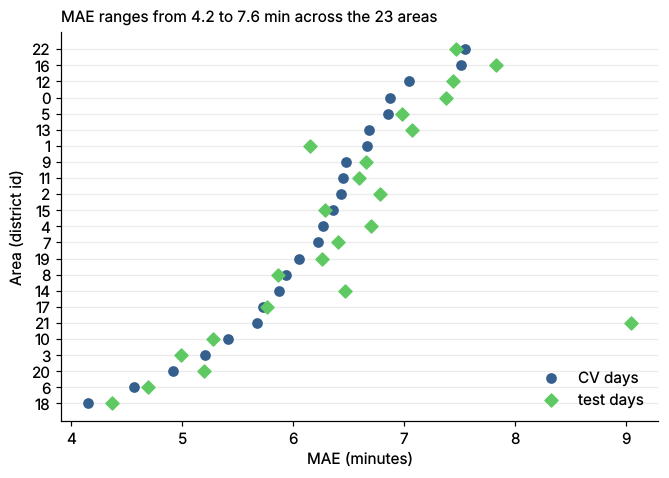

In [4]:
area = by("district")
order = area["CV"]["mae"].sort_values().index
display(area.loc[order].round(2))

fig, ax = plt.subplots(figsize=(7, 4.6))
y = np.arange(len(order))
for i, ev in enumerate(runs):
    ax.scatter(area.loc[order, (ev, "mae")], y, color=C[ev], label=f"{ev} days", zorder=3,
               marker="o" if ev == "CV" else "D")
ax.set_yticks(y, [str(a) for a in order])
ax.set_ylabel("Area (district id)")
ax.set_xlabel("MAE (minutes)")
lo, hi = area["CV"]["mae"].min(), area["CV"]["mae"].max()
ax.set_title(f"MAE ranges from {lo:.1f} to {hi:.1f} min across the 23 areas", fontsize=10, loc="left")
ax.grid(axis="y", color="0.92")
ax.legend(frameon=False, loc="lower right")
save(fig, "errors_by_area")
plt.show()

**Reading:** on the test days MAE goes from 4.37 min in area 18 to 9.04 in area 21. Areas 18 and 6 are the
short-trip areas from EDA §3. Area 16 is bad on both CV (7.51) and test (7.83), and we predict it 3.8 min too
short on the test days, the same area EDA §3 found slow even at the same distance. Area 21 is a surprise: 5.67 on
CV but 9.04 on test. That comes from Sunday 23 only (11.3 min, 9.2 min too short) while Monday is normal (6.2), so
it looks like a one-day event there, not a stable problem. For the ethics paragraph: customers in areas 16, 12
and 0 get ETAs about 3 min worse than in area 18 on both CV and test.

## 4. Errors by day (weekend caution)

In [5]:
day = pd.concat({ev: p.groupby("day").agg(n=("y", "size"), mae=("abs_err", "mean"), bias=("err", "mean"))
                 for ev, p in runs.items()})
day.round(2)

n   mae  bias
     day                        
CV   20221019  65863  6.09 -0.36
     20221020  65981  6.00 -0.57
     20221021  69270  6.43 -1.60
     20221022  74848  6.44 -1.52
test 20221023  75063  6.77 -2.14
     20221024  64724  6.17 -0.48

**Reading:** Sunday 23 is the hardest day: MAE 6.77, and we predict 2.1 min too short on average. Monday 24 is
6.17, close to the weekdays in CV (6.00 to 6.09). That matches what EDA §10 expected: the model only saw one
weekend day (Sat 22) in training, so it can't learn the weekend, and Sunday is where the test MAE (6.49) goes above
CV (6.25).

## 5. Residuals: is the model biased?

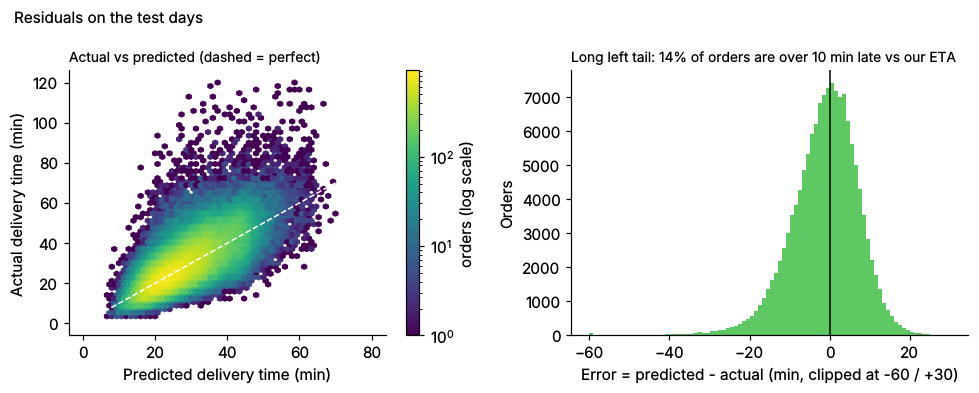

median error -0.62, mean -1.37, 10th pct -11.9, 90th pct +8.4


In [6]:
ev = "test" if "test" in runs else "CV"
p = runs[ev]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
hb = axes[0].hexbin(p["pred"], p["y"], gridsize=60, bins="log", cmap="viridis", mincnt=1,
                    extent=(0, 80, 0, 120))
axes[0].plot([0, 80], [0, 80], color="white", lw=1, ls="--")
axes[0].set_xlabel("Predicted delivery time (min)")
axes[0].set_ylabel("Actual delivery time (min)")
axes[0].set_title("Actual vs predicted (dashed = perfect)", fontsize=9, loc="left")
fig.colorbar(hb, ax=axes[0], label="orders (log scale)")

axes[1].hist(p["err"].clip(-60, 30), bins=90, color=C[ev])
axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("Error = predicted - actual (min, clipped at -60 / +30)")
axes[1].set_ylabel("Orders")
under = (p["err"] < -10).mean()
axes[1].set_title(f"Long left tail: {under:.0%} of orders are over 10 min late vs our ETA", fontsize=9, loc="left")
fig.suptitle(f"Residuals on the {ev} days", fontsize=10, x=0.02, ha="left")
fig.tight_layout()
save(fig, "residuals")
plt.show()
print(f"median error {p.err.median():+.2f}, mean {p.err.mean():+.2f}, 10th pct {p.err.quantile(.1):+.1f}, "
      f"90th pct {p.err.quantile(.9):+.1f}")

**Reading:** on the test days the median error is −0.62 min, close to 0 as expected from absolute loss. The mean
is −1.37 because of a long left tail: 13.8% of orders arrive more than 10 min after our ETA (CV 12%), while the
90th percentile of errors is only +8.4. The model is rarely very early but sometimes very late.

## 6. The worst orders

In [7]:
for ev, p in runs.items():
    cut = p["abs_err"].quantile(0.99)
    worst = p[p["abs_err"] >= cut]
    rest = p[p["abs_err"] < cut]
    print(f"{ev}: worst 1% = {len(worst):,} orders with error >= {cut:.1f} min, "
          f"{(worst.err < 0).mean():.0%} of them late (we predicted too short)")
    display(pd.DataFrame({"worst 1%": worst[["y", "pred", "dist_km", "hour"]].median(),
                          "other 99%": rest[["y", "pred", "dist_km", "hour"]].median()}).round(1))

CV: worst 1% = 2,760 orders with error >= 25.4 min, 97% of them late (we predicted too short)


,worst 1%,other 99%
y,63.6,27.7
pred,31.4,27.5
dist_km,1.7,1.5
hour,15.0,15.0


test: worst 1% = 1,398 orders with error >= 26.2 min, 98% of them late (we predicted too short)


,worst 1%,other 99%
y,64.2,28.1
pred,31.2,27.7
dist_km,1.7,1.5
hour,14.0,14.0


**Reading:** the worst 1% (error 26.2 min or more on test, 25.4 on CV) are almost all late orders (98%). They
took a median of 64 min but we predicted 31, yet their trips are barely longer (1.7 vs 1.5 km) and at the same
hour. So they are not unusual orders; something happened after the order (courier or restaurant delay) that we
can't see at order time. That is the same gap the leakage audit (S5) measures.

## Summary for the Results section (M8)

1. On the test days HGB gets MAE 6.49 min vs 9.62 for the platform's promise; CV was 6.25, so the test is only
   0.24 worse, almost all from Sunday 23 (6.77; Monday 6.17).
2. Errors rise at meal peaks: 7.22 at the lunch peak and 6.86 at dinner vs 6.08 off-peak (test).
3. Errors grow with distance: 5.61 under 1 km, 14.37 over 7 km (test).
4. Areas differ: 4.37 (area 18) to 7.83 (area 16, slow at any distance); area 21 jumps to 9.04 on Sunday only.
5. The model is biased short: median error −0.62, but 13.8% of orders are over 10 min later than our ETA, and the
   worst 1% are late orders that look normal at order time.